**Summary**

1. The test set (steps 36 to 49) came entirely after the training data (steps 1 to 35), so I always trained on earlier steps and validate on later ones. I used 2 sets of folds: 6 rolling folds that start early and 5 later-origin folds that start at step 24 or later.

2. **Baseline Model**: A LightGBM + XGBoost + CatBoost ensemble trained on the labelled transactions scores 0.950 on the public leaderboard.

4. **Final Model**: I used the unlabelled transactions the other way round: a second ensemble learns illicit vs everything else, with the 110,537 unlabelled transactions as extra negatives. Blending it with the baseline raised the public score from 0.950 to 0.962.

## 1. Setup

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, QuantileTransformer
import lightgbm as lgb
import xgboost as xgb
import catboost as cb

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

In [2]:
SEED = 0
N_JOBS = os.cpu_count()
RUN_EXTRA = True
OUT_DIR = "."

# smoothing constant of the licit-detector combination rule (Section 7)
EPS = 0.01    

# final model: supervised ensemble blended with the illicit-vs-rest ensemble (Section 10)

# which version of the two component ensembles: "default", "slow", or "both" (average of the 2)
FINAL_SET = "both"  
# weight of the illicit-vs-rest ensemble in the logit blend 
FINAL_W = 1.0       

os.makedirs(f"{OUT_DIR}/figures", exist_ok=True)
np.random.seed(SEED)

# chart style: one colour per entity, used consistently in every figure
# classes
C_LICIT, C_ILLICIT = "#2a78d6", "#eb6834"    
# models: supervised only, licit detector only, combined            
C_SUP, C_LIC, C_COMB = "#eda100", "#1baf7a", "#4a3aa7"    
# illicit-vs-rest blend (final model)
C_IR = "#4a3aa7"                                         
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.edgecolor": "#8a8a86", "xtick.color": "#52514e", "ytick.color": "#52514e"})

## 2. Load the data
`label` is 1 for illicit, 0 for licit and missing for unknown. Test rows have no label, but by construction every test row is a labelled transaction (the hidden label is licit or illicit, never unknown).

In [3]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
edges = pd.read_csv("txs_edgelist.csv")
sample_sub = pd.read_csv("sample_submission.csv")

FEATS = [f"feat_{i}" for i in range(1, 166)]
train["label"] = pd.to_numeric(train["label"], errors="coerce") 

# test steps come after all the train steps -> validate out of time (train on early steps, test on later ones)
print("train steps", train.time_step.min(), "-", train.time_step.max())
print("test steps", test.time_step.min(), "-", test.time_step.max())

# One frame holding every transaction that has features. `labelled` marks membership of the labelled set:
# train rows with a known label, and all test rows.
nodes = pd.concat([train.assign(is_test=0), test.drop(columns=["index"]).assign(label=np.nan, is_test=1)], ignore_index=True)
nodes["labelled"] = (nodes.label.notna() | (nodes.is_test == 1)).astype(int)

train steps 1 - 35
test steps 36 - 49


## 3. Transaction graph and graph features

An edge `txId1 -> txId2` means `txId2` spends an output of `txId1`. I build the graph from the full edge list, which covers 203,769 transactions. Around 46,700 of them have no features in either file (they are the unlabelled test-period transactions that weren't released), but I kept them as they still show how the other transactions are connected.

In [4]:
# Return adjacency A (A[i, j] = 1 if i -> j) over every transaction in the edge list, and the row id of each node.
def build_graph(nodes, edges):
    ids = pd.Index(np.unique(np.concatenate([edges.txId1.values, edges.txId2.values, nodes.txId.values])))
    pos = pd.Series(np.arange(len(ids)), index=ids)
    src, dst = pos.loc[edges.txId1].values, pos.loc[edges.txId2].values
    A = sp.csr_matrix((np.ones(len(src), dtype=np.float32), (src, dst)), shape=(len(ids), len(ids)))
    return A, pos.loc[nodes.txId].values

A, nid = build_graph(nodes, edges)
nodes["nid"] = nid
N = A.shape[0]
# predecessors
AT = A.T.tocsr() 
# undirected view           
U = (A + AT).tocsr()       

G = nx.from_scipy_sparse_array(A, create_using=nx.DiGraph)
n_comp, comp = connected_components(U, directed=False)

Structural features were then added based on the graph's shape: degrees, 2- and 3-hop reach, co-spending, neighbour degree statistics, chains, depth in the graph, PageRank, k-core, and clustering.

In [5]:
# Structural features for every transaction in the graph. They use no labels, and the edge list is complete, so they are computed the same way for train and test.
def structural_features(A, G, comp):
    AT = A.T.tocsr()
    U = (A + AT).tocsr()
    N = A.shape[0]
    one = np.ones(N, dtype=np.float32)
    S = {}

    # degree: number of funding (in) and spending (out) transactions
    S["indeg"] = np.asarray(A.sum(0)).ravel()
    S["outdeg"] = np.asarray(A.sum(1)).ravel()
    S["deg"] = S["indeg"] + S["outdeg"]

    # walks of length 2 and 3: how much activity sits upstream / downstream
    S["pred2"], S["succ2"] = AT @ (AT @ one), A @ (A @ one)
    S["pred3"], S["succ3"] = AT @ (AT @ (AT @ one)), A @ (A @ (A @ one))

    # siblings: transactions spent together with this one, or paid by the same transaction
    S["sib_out"] = A @ (AT @ one) - S["outdeg"]
    S["sib_in"] = AT @ (A @ one) - S["indeg"]

    # number of distinct transactions within two hops
    U2 = (U @ U).tocsr()
    U2.setdiag(0)
    U2.eliminate_zeros()
    S["n2hop"] = np.diff(U2.indptr).astype(float)

    # mean and max degree of the predecessors and successors
    for name, M, cnt in [("pred", AT, S["indeg"]), ("succ", A, S["outdeg"])]:
        Mc = M.tocoo()
        for v in ["indeg", "outdeg"]:
            S[f"{name}_mean_{v}"] = np.where(cnt > 0, (M @ S[v]) / np.maximum(cnt, 1), np.nan)
            mx = np.full(N, -np.inf)
            np.maximum.at(mx, Mc.row, S[v][Mc.col])
            mx[~np.isfinite(mx)] = np.nan
            S[f"{name}_max_{v}"] = mx

    # chains: one-in-one-out transactions are the links of "peeling chains"
    chain = ((S["indeg"] == 1) & (S["outdeg"] == 1)).astype(np.float32)
    S["is_chain"] = chain
    S["is_source"] = (S["indeg"] == 0).astype(float)
    S["is_sink"] = (S["outdeg"] == 0).astype(float)
    S["chain_nbr_frac"] = (U @ chain) / np.maximum(S["deg"], 1)

    # position in the graph: longest path from a source (depth) and to a sink (height)
    depth, height = np.zeros(N), np.zeros(N)
    order = list(nx.topological_sort(G))
    for u in order:
        for v in A.indices[A.indptr[u]:A.indptr[u + 1]]:
            depth[v] = max(depth[v], depth[u] + 1)
    for u in reversed(order):
        for v in A.indices[A.indptr[u]:A.indptr[u + 1]]:
            height[u] = max(height[u], height[v] + 1)
    S["depth"], S["height"] = depth, height

    # depth and height relative to the longest path in the same time step
    longest = pd.Series(depth + height).groupby(comp).transform("max").values
    S["depth_rel"] = depth / np.maximum(longest, 1)
    S["height_rel"] = height / np.maximum(longest, 1)

    # centrality
    to_arr = lambda d: np.array([d[i] for i in range(N)], dtype=float)
    S["pagerank"] = to_arr(nx.pagerank(G, alpha=0.85, max_iter=200)) * N
    S["pagerank_rev"] = to_arr(nx.pagerank(G.reverse(copy=False), alpha=0.85, max_iter=200)) * N
    UG = G.to_undirected()
    S["kcore"] = to_arr(nx.core_number(UG))
    S["clustering"] = to_arr(nx.clustering(UG))
    return pd.DataFrame(S)

S_all = structural_features(A, G, comp)
STRUCT = list(S_all.columns)
nodes = pd.concat([nodes, S_all.iloc[nodes.nid.values].reset_index(drop=True)], axis=1)

### Neighbour-attribute and label-neighbourhood features (used in ablations only)
Two further families are built for the ablation study in section 6 (but not part of the final model):

* `LABNB`: how many of a transaction's neighbours belong to the labelled set

* `NBMEAN`: the average of each local feature over a transaction's predecessors, and separately over its successors. I only average over labelled neighbours as in the test period, those are the only ones with features. Hence, this keeps the feature calculated the same way in train and test.

In [6]:
LOCAL = FEATS[:93]
lab_mask = np.zeros(N, dtype=np.float32); lab_mask[nodes.nid.values] = nodes.labelled.values
one = np.ones(N, dtype=np.float32)
indeg, outdeg = S_all["indeg"].values, S_all["outdeg"].values
Lb = {}
Lb["lab_pred"] = AT @ lab_mask; Lb["lab_succ"] = A @ lab_mask; Lb["lab_nbr"] = Lb["lab_pred"] + Lb["lab_succ"]
Lb["frac_lab_pred"] = np.where(indeg > 0, Lb["lab_pred"] / np.maximum(indeg, 1), np.nan)
Lb["frac_lab_succ"] = np.where(outdeg > 0, Lb["lab_succ"] / np.maximum(outdeg, 1), np.nan)
Lb["frac_lab_nbr"] = Lb["lab_nbr"] / np.maximum(indeg + outdeg, 1)
Lb["lab3walk_frac"] = (U @ (U @ (U @ lab_mask))) / np.maximum(U @ (U @ (U @ one)), 1)
Lb = pd.DataFrame(Lb); LABNB = list(Lb.columns)
nodes = pd.concat([nodes, Lb.iloc[nodes.nid.values].reset_index(drop=True)], axis=1)

NBMEAN = []
if RUN_EXTRA:
    X_all = np.zeros((N, len(LOCAL)), dtype=np.float32); X_all[nodes.nid.values] = nodes[LOCAL].values
    X_lab = X_all * lab_mask[:, None]
    agg = {}
    for name, M in [("pred", AT), ("succ", A)]:
        cnt = M @ lab_mask
        mean = (M @ X_lab) / np.maximum(cnt, 1)[:, None]; mean[cnt == 0] = np.nan
        for j, f in enumerate(LOCAL): agg[f"{name}_mean_{f}"] = mean[nodes.nid.values, j]
    agg = pd.DataFrame(agg); NBMEAN = list(agg.columns)
    nodes = pd.concat([nodes, agg], axis=1)
    del X_all, X_lab, agg
    
print("label-neighbourhood features:", len(LABNB))
print("neighbour-mean features:", len(NBMEAN))

label-neighbourhood features: 7
neighbour-mean features: 186


## 4. Validation Design

The test set covers time steps 36 to 49 and the model is trained on steps 1 to 35, thus I copied that setup inside the training data: train on every step up to `a`, then score the labelled transactions in the steps after it. 

I use 2 sets of folds:

* **Rolling folds** (a = 5, 10, ..., 30) start early and look up to 14 steps ahead. Some of them hit completely new illicit patterns (see section 5), so they test how the model copes with something it hasn't seen.

* **Later-origin folds** (a = 24, 26, 28, 30, 32) run to step 35. By then the model has seen every illicit pattern in the validation window, so they test how well it ranks familiar activity.

I first picked models using the rolling folds, but section 9 shows that the later-origin folds were the ones that were more reliable. 


In [7]:
ROLL = [(5, 6, 19), (10, 11, 24), (15, 16, 29), (20, 21, 34), (25, 26, 35), (30, 31, 35)]
LATE = [(24, 25, 35), (26, 27, 35), (28, 29, 35), (30, 31, 35), (32, 33, 35)]
ALL = ROLL + [f for f in LATE if f not in ROLL]
fname = lambda f: f"<={f[0]} -> {f[1]}-{f[2]}"
TR = nodes[nodes.is_test == 0]
TE = nodes[nodes.is_test == 1]

def split(fold):
    """Training pool (all transactions up to step a, labelled or not) and labelled validation rows of steps b..c."""
    a, b, c = fold
    return TR[TR.time_step <= a], TR[(TR.time_step >= b) & (TR.time_step <= c) & TR.label.notna()]

Y_VAL = {f: split(f)[1].label.values for f in ALL}

# Model factories
def lgbm(**kw):
    p = dict(n_estimators=400, learning_rate=0.03, num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
             verbose=-1, n_jobs=N_JOBS, random_state=SEED, deterministic=True, force_row_wise=True); p.update(kw)
    return lambda: lgb.LGBMClassifier(**p)

def xgbm(**kw):
    p = dict(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.5, tree_method="hist",
             n_jobs=N_JOBS, random_state=SEED); p.update(kw)
    return lambda: xgb.XGBClassifier(**p)

def catb(**kw):
    p = dict(iterations=500, learning_rate=0.08, depth=6, verbose=0, thread_count=N_JOBS, random_seed=SEED, allow_writing_files=False); p.update(kw)
    return lambda: cb.CatBoostClassifier(**p)

def logreg():
    return make_pipeline(QuantileTransformer(output_distribution="normal", n_quantiles=200, random_state=SEED),
                         LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced"))

def rf():
    return RandomForestClassifier(300, n_jobs=N_JOBS, random_state=SEED)

def mlp():
    return make_pipeline(QuantileTransformer(output_distribution="normal", n_quantiles=200, subsample=50000, random_state=SEED),
                         MLPClassifier((128, 64), alpha=1e-2, early_stopping=True, random_state=SEED, max_iter=60))

# The 2 versions of each gradient-boosting ensemble used in sections 8 to 10.
# "default": moderate settings.  "slow": lower learning rate, more trees.
SETS = {
    "default": {"sup": [("lgb", lgbm()), ("xgb", xgbm()), ("cat", catb())], "ir":  [("lgb", lgbm()), ("xgb", xgbm()), ("cat", catb())]},
    "slow": {"sup": [("lgb", lgbm(learning_rate=0.02, n_estimators=1000)), ("xgb", xgbm(max_depth=4, n_estimators=800)), ("cat", catb(iterations=1500, learning_rate=0.05))],
            "ir":  [("lgb", lgbm(learning_rate=0.02, n_estimators=1000)), ("xgb", xgbm(learning_rate=0.02, n_estimators=1000)), ("cat", catb(iterations=1500, learning_rate=0.05))]},
}

# Component runner 
# name -> {fold: validation predictions}
PRED = {}   

# rows of the model comparison table
RESULTS = []   

# sup: illicit vs licit on labelled rows. 
# lic: licit vs everything else on all rows.
# ir: illicit vs everything else on all rows (unlabelled transactions count as negatives).
def target_of(tr_all, target):
    if target == "sup":
        tr = tr_all[tr_all.label.notna()]
        return tr, tr.label.values.astype(int)
    if target == "lic":
        return tr_all, (tr_all.label == 0).astype(int).values
    return tr_all, (tr_all.label == 1).astype(int).values

# Fit one component on each fold and store its out-of-time validation predictions.
def run_cv(name, target, cols, make_model, folds=ALL):
    t = time.time(); out = PRED.setdefault(name, {})
    for f in folds:
        if f in out: continue
        tr_all, val = split(f)
        tr, y = target_of(tr_all, target)
        out[f] = make_model().fit(tr[cols].values, y).predict_proba(val[cols].values)[:, 1]
    print(f"  fitted {name} on {len(folds)} folds ({time.time()-t:.0f}s)")
    return out

lgt = lambda p, e=1e-4: np.log((p + e) / (1 - p + e))
sigmoid = lambda z: 1 / (1 + np.exp(-z))

def average(names, folds=ALL):
    return {f: np.mean([PRED[n][f] for n in names], axis=0) for f in folds}

# Final model: logit blend of the supervised and illicit-vs-rest ensembles (w = weight of illicit-vs-rest).
def blend(sup, ir, w, folds=ALL):
    return {f: (1 - w) * lgt(sup[f]) + w * lgt(ir[f]) for f in folds}

# Licit-detector rule of section 7: smoothed share of illicit evidence among the two labelled classes.
def combine(p_ill, p_lic, eps=EPS):
    return (p_ill + eps) / (p_ill + p_lic + 2 * eps)

# AUC among validation rows the default supervised ensemble scores below 0.5
def low_range_auc(f, s):
    m = PRED["sup_ens"][f] < 0.5
    return roc_auc_score(Y_VAL[f][m], s[m]) if Y_VAL[f][m].sum() > 0 else np.nan

def evaluate(label, scores, family="rolling", group="", keep=True):
    folds = ROLL if family == "rolling" else LATE
    folds = [f for f in folds if f in scores]
    aucs = [roc_auc_score(Y_VAL[f], scores[f]) for f in folds]
    row = {"family": family, "group": group, "model": label, **{fname(f): round(a, 4) for f, a in zip(folds, aucs)},
           "mean AUC": round(np.mean(aucs), 4), "worst AUC": round(np.min(aucs), 4)}
    extra = ""
    if family == "later" and "sup_ens" in PRED:
        lr_ = np.nanmean([low_range_auc(f, scores[f]) for f in folds]); row["low-range AUC"] = round(lr_, 4); extra = f" | low-range {lr_:.4f}"
    if keep: RESULTS.append(row)
    print(f"{label:58s} " + " ".join(f"{a:.4f}" for a in aucs) + f" | mean {np.mean(aucs):.4f} | worst {np.min(aucs):.4f}" + extra)
    return row

def header(family):
    print(" " * 59 + "  ".join(fname(f) for f in (ROLL if family == "rolling" else LATE)))

## 5. Supervised models (illicit vs licit, labelled rows only)

In [8]:
header("rolling")
for k, mk in SETS["default"]["sup"]:
    run_cv(f"sup_{k}", "sup", FEATS, mk)
PRED["sup_ens"] = average(["sup_lgb", "sup_xgb", "sup_cat"])
if RUN_EXTRA:
    for label, name, mk in [("Logistic regression", "sup_lr", logreg), ("Random forest", "sup_rf", rf)]:
        run_cv(name, "sup", FEATS, mk, folds=ROLL)
    run_cv("sup_mlp", "sup", FEATS, mlp)
    for label, name in [("Logistic regression", "sup_lr"), ("Random forest", "sup_rf"), ("MLP (128, 64)", "sup_mlp")]:
        evaluate(f"{label} [raw 165]", PRED[name], group="A. supervised")
for label, name in [("LightGBM", "sup_lgb"), ("XGBoost", "sup_xgb"), ("CatBoost", "sup_cat"), ("Supervised ensemble (LGBM + XGB + CatBoost)", "sup_ens")]:
    evaluate(f"{label} [raw 165]", PRED[name], group="A. supervised")
header("later")
evaluate("Supervised ensemble (LGBM + XGB + CatBoost)", PRED["sup_ens"], family="later", group="A. supervised")

                                                           <=5 -> 6-19  <=10 -> 11-24  <=15 -> 16-29  <=20 -> 21-34  <=25 -> 26-35  <=30 -> 31-35
  fitted sup_lgb on 10 folds (42s)
  fitted sup_xgb on 10 folds (16s)
  fitted sup_cat on 10 folds (36s)
  fitted sup_lr on 6 folds (7s)
  fitted sup_rf on 6 folds (10s)
  fitted sup_mlp on 10 folds (20s)
Logistic regression [raw 165]                              0.9528 0.9685 0.9303 0.8559 0.9415 0.9653 | mean 0.9357 | worst 0.8559
Random forest [raw 165]                                    0.9185 0.9497 0.8755 0.7544 0.9922 0.9968 | mean 0.9145 | worst 0.7544
MLP (128, 64) [raw 165]                                    0.9208 0.9784 0.9626 0.9174 0.9843 0.9882 | mean 0.9586 | worst 0.9174
LightGBM [raw 165]                                         0.9192 0.9676 0.9216 0.8776 0.9964 0.9984 | mean 0.9468 | worst 0.8776
XGBoost [raw 165]                                          0.9415 0.9659 0.8766 0.8581 0.9962 0.9979 | mean 0.9394 | worst 0.8581

{'family': 'later',
 'group': 'A. supervised',
 'model': 'Supervised ensemble (LGBM + XGB + CatBoost)',
 '<=24 -> 25-35': np.float64(0.9975),
 '<=26 -> 27-35': np.float64(0.998),
 '<=28 -> 29-35': np.float64(0.9976),
 '<=30 -> 31-35': np.float64(0.9987),
 '<=32 -> 33-35': np.float64(0.9977),
 'mean AUC': np.float64(0.9979),
 'worst AUC': np.float64(0.9975),
 'low-range AUC': np.float64(0.9734)}

The cell below takes LightGBM trained on steps 1 to 20 and reports AUC separately for every later step.

In [9]:
def per_step_auc(val, score):
    return pd.Series({t: roc_auc_score(g.label, score[(val.time_step == t).values]) for t, g in val.groupby("time_step")})

# LightGBM trained on steps 1-20, scored on each later step separately
f20 = (20, 21, 34)
_, val20 = split(f20)
p = PRED["sup_lgb"][f20]
drift = pd.DataFrame({"illicit count": val20.groupby("time_step").label.sum().astype(int).astype(str),
                      "supervised AUC": per_step_auc(val20, p).map("{:.3f}".format)})
print(drift.T.to_string())

# illicit transactions in the steps where AUC drops: what do the missed ones look like?
hard = val20.time_step.isin([24, 29, 31, 32]).values & (val20.label.values == 1)
print(f"\nillicit transactions in steps 24/29/31/32: {hard.sum()}, of which scored below 0.05: {(p[hard] < 0.05).sum()}")
cols = ["indeg", "outdeg", "is_chain", "depth_rel", "feat_53"]
print(pd.DataFrame({"missed illicit": val20[hard & (p < 0.05)][cols].mean(),
                    "caught illicit": val20[hard & (p >= 0.5)][cols].mean(),
                    "licit": val20[val20.label == 0][cols].mean()}).round(3))

                   21     22     23     24     25     26     27     28     29     30     31     32     33     34
illicit count     100    158     53    137    118     96     24     85    329     83    106    342     23     37
supervised AUC  0.995  0.999  0.953  0.749  1.000  0.926  1.000  1.000  0.702  0.991  0.725  0.763  0.993  0.998

illicit transactions in steps 24/29/31/32: 914, of which scored below 0.05: 426
           missed illicit  caught illicit  licit
indeg               1.085           0.811  1.712
outdeg              1.099           0.696  1.156
is_chain            0.826           0.242  0.186
depth_rel           0.359           0.013  0.047
feat_53             0.975          -0.471  1.189


The failure is concentrated in steps 24, 29, 31 and 32, where AUC drops to about 0.7 while almost every other step
stays above 0.95. In those steps close to half of the illicit transactions get a score below 0.05. They are a **new
typology**: links of long one-in-one-out chains deep inside the DAG, with `feat_53` values that earlier data
associated with licit transactions. Once a few examples enter training (the folds starting at 25 or 30) they become
trivial to detect. The supervised model has learned the signatures of specific illicit actors, not what makes a
transaction illicit.

## 6. Graph feature ablation
Supervised LightGBM with the structural features, then the label-neighbourhood counts, then the neighbour means.

In [10]:
if RUN_EXTRA:
    header("rolling")
    evaluate("LightGBM [raw]", PRED["sup_lgb"], group="B. graph features")
    for label, name, cols in [("LightGBM [raw + structural]", "sup_lgb_struct", FEATS + STRUCT),
                              ("LightGBM [raw + structural + label-neighbourhood]", "sup_lgb_struct_lab", FEATS + STRUCT + LABNB),
                              ("LightGBM [raw + structural + neighbour means]", "sup_lgb_nbmean", FEATS + STRUCT + NBMEAN)]:
        run_cv(name, "sup", cols, lgbm(), folds=ROLL)
        evaluate(label, PRED[name], group="B. graph features")
    run_cv("sup_lgb_struct", "sup", FEATS + STRUCT, lgbm(), folds=LATE)
    header("later")
    evaluate("LightGBM [raw]", PRED["sup_lgb"], family="later", group="B. graph features")
    evaluate("LightGBM [raw + structural]", PRED["sup_lgb_struct"], family="later", group="B. graph features")

                                                           <=5 -> 6-19  <=10 -> 11-24  <=15 -> 16-29  <=20 -> 21-34  <=25 -> 26-35  <=30 -> 31-35
LightGBM [raw]                                             0.9192 0.9676 0.9216 0.8776 0.9964 0.9984 | mean 0.9468 | worst 0.8776
  fitted sup_lgb_struct on 6 folds (25s)
LightGBM [raw + structural]                                0.9371 0.9683 0.9122 0.8735 0.9968 0.9986 | mean 0.9477 | worst 0.8735
  fitted sup_lgb_struct_lab on 6 folds (25s)
LightGBM [raw + structural + label-neighbourhood]          0.9489 0.9707 0.9272 0.8761 0.9968 0.9986 | mean 0.9530 | worst 0.8761
  fitted sup_lgb_nbmean on 6 folds (32s)
LightGBM [raw + structural + neighbour means]              0.9421 0.9676 0.9003 0.8411 0.9969 0.9987 | mean 0.9411 | worst 0.8411
  fitted sup_lgb_struct on 5 folds (18s)
                                                           <=24 -> 25-35  <=26 -> 27-35  <=28 -> 29-35  <=30 -> 31-35  <=32 -> 33-35
LightGBM [raw]                   

Structural features give a small gain on the rolling folds and none on the later-origin folds; neighbour means make
things worse. Features 94 to 165 are already one-hop aggregates computed by the organisers on the complete
neighbourhood, and no feature can teach a supervised model a typology it has never seen. The final model therefore
uses the 165 provided features only.

### Features that encode time
I excluded `time_step` as a feature, but some of the provided features turn out to be time stamps in disguise.

In [11]:
sp_time = TR[FEATS].iloc[::5].corrwith(TR.time_step.iloc[::5], method="spearman")
TIME_PROXY = list(sp_time[sp_time.abs() > 0.8].index)
lo, hi = TR[TIME_PROXY].quantile(0.001), TR[TIME_PROXY].quantile(0.999)
outside = ((TE[TIME_PROXY] < lo) | (TE[TIME_PROXY] > hi)).mean()
print(pd.DataFrame({"Spearman with time step": sp_time[TIME_PROXY].round(3), "test rows outside training range": outside.round(3)}).to_string())
if RUN_EXTRA:
    NO_TIME = [f for f in FEATS if f not in TIME_PROXY]
    run_cv("sup_lgb_notime", "sup", NO_TIME, lgbm())
    for fam in ["rolling", "later"]:
        header(fam)
        evaluate("LightGBM [raw]", PRED["sup_lgb"], family=fam, group="B. graph features", keep=False)
        evaluate("LightGBM [raw without the time proxies]", PRED["sup_lgb_notime"], family=fam, group="B. graph features")

          Spearman with time step  test rows outside training range
feat_100                    0.993                             0.992
feat_101                    0.997                             0.995
feat_103                    0.995                             0.994
feat_136                    0.995                             0.009
feat_137                    0.896                             0.005
feat_139                    0.956                             0.009
  fitted sup_lgb_notime on 10 folds (40s)
                                                           <=5 -> 6-19  <=10 -> 11-24  <=15 -> 16-29  <=20 -> 21-34  <=25 -> 26-35  <=30 -> 31-35
LightGBM [raw]                                             0.9192 0.9676 0.9216 0.8776 0.9964 0.9984 | mean 0.9468 | worst 0.8776
LightGBM [raw without the time proxies]                    0.9328 0.9676 0.9268 0.8783 0.9963 0.9982 | mean 0.9500 | worst 0.8783
                                                           <=24 -> 25-35  <=

6 features rise almost in step with time, and for 3 of them nearly every test value is outside the training range, so a tree model puts almost all test rows on the "latest period" side of any split on them. Dropping them barely changes validation, since the validation folds run into the same problem. Hence, I kept all 165 features but listed this as a risk in the report.

## 7. Attempt 1 of using the unlabelled pool: a licit detector (rejected)

Every test transaction is either licit or illicit. Licit transactions come from known services that stay around for a long time, while illicit ones appear and disappear. Therefore, I trained a second model on all training rows to tell licit transactions (1) apart from everything else (0). I then combined it with the supervised model as `(p_ill + eps) / (p_ill + p_lic + 2 eps)`.

In [12]:
if RUN_EXTRA:
    for k, mk in SETS["default"]["sup"]:
        run_cv(f"lic_{k}", "lic", FEATS, mk)
    PRED["lic_ens"] = average(["lic_lgb", "lic_xgb", "lic_cat"])
    for fam in ["rolling", "later"]:
        header(fam)
        evaluate("Supervised ensemble", PRED["sup_ens"], family=fam, group="C. licit detector", keep=False)
        evaluate("Licit detector alone (1 - p_lic)", {f: 1 - PRED["lic_ens"][f] for f in ALL}, family=fam, group="C. licit detector")
        evaluate("Supervised x licit detector (ratio rule)", {f: combine(PRED["sup_ens"][f], PRED["lic_ens"][f]) for f in ALL}, family=fam, group="C. licit detector")

  fitted lic_lgb on 10 folds (62s)
  fitted lic_xgb on 10 folds (32s)
  fitted lic_cat on 10 folds (77s)
                                                           <=5 -> 6-19  <=10 -> 11-24  <=15 -> 16-29  <=20 -> 21-34  <=25 -> 26-35  <=30 -> 31-35
Supervised ensemble                                        0.9321 0.9649 0.9029 0.8393 0.9969 0.9987 | mean 0.9391 | worst 0.8393
Licit detector alone (1 - p_lic)                           0.9659 0.9749 0.9787 0.9777 0.9707 0.9693 | mean 0.9729 | worst 0.9659
Supervised x licit detector (ratio rule)                   0.9746 0.9879 0.9841 0.9788 0.9938 0.9961 | mean 0.9859 | worst 0.9746
                                                           <=24 -> 25-35  <=26 -> 27-35  <=28 -> 29-35  <=30 -> 31-35  <=32 -> 33-35
Supervised ensemble                                        0.9975 0.9980 0.9976 0.9987 0.9977 | mean 0.9979 | worst 0.9975 | low-range 0.9734
Licit detector alone (1 - p_lic)                           0.9704 0.9750 0.9678 0.96

On the rolling folds this looked like a breakthrough. The worst fold jumped from about 0.84 to about 0.98 as the new illicit chains from section 6 do not look like either class, which is  what this rule flags. However, it did worse on the later-origin folds than the supervised ensemble alone, scoring only 0.92 on the public leaderboard compared to 0.950 for the supervised ensemble (refer to section 9). This is most likely because in the test period, most transactions that do not look like either class are actually licit.

## 8. Attempt 2 of using the unlabelled pool: illicit vs everything else

This time I used the unlabelled data the other way round. I trained a second ensemble on all training rows to separate illicit transactions (1) from everything else (0), so the 110,537 unlabelled transactions count as extra negatives. This shows the model what normal Bitcoin activity looks like. If a transaction looks like that normal background, its score goes down, even when the supervised model (which never saw the unlabelled rows) is not sure about it.

I then blend the two ensembles: `score = (1 - w) * logit(p_sup) + w * logit(p_ir)`.

In [13]:
for k, mk in SETS["default"]["ir"]:
    run_cv(f"ir_{k}", "ir", FEATS, mk)
PRED["ir_ens"] = average(["ir_lgb", "ir_xgb", "ir_cat"])
for fam in ["later", "rolling"]:
    header(fam)
    evaluate("Supervised ensemble", PRED["sup_ens"], family=fam, group="D. illicit vs rest", keep=(fam == "later"))
    evaluate("Illicit-vs-rest ensemble alone", PRED["ir_ens"], family=fam, group="D. illicit vs rest")
    for w in [0.5, 0.65, 0.8]:
        evaluate(f"Blend, w = {w}", blend(PRED["sup_ens"], PRED["ir_ens"], w), family=fam, group="D. illicit vs rest")

  fitted ir_lgb on 10 folds (61s)
  fitted ir_xgb on 10 folds (32s)
  fitted ir_cat on 10 folds (78s)
                                                           <=24 -> 25-35  <=26 -> 27-35  <=28 -> 29-35  <=30 -> 31-35  <=32 -> 33-35
Supervised ensemble                                        0.9975 0.9980 0.9976 0.9987 0.9977 | mean 0.9979 | worst 0.9975 | low-range 0.9734
Illicit-vs-rest ensemble alone                             0.9947 0.9963 0.9956 0.9989 0.9987 | mean 0.9968 | worst 0.9947 | low-range 0.9754
Blend, w = 0.5                                             0.9983 0.9987 0.9983 0.9993 0.9987 | mean 0.9986 | worst 0.9983 | low-range 0.9824
Blend, w = 0.65                                            0.9982 0.9986 0.9983 0.9993 0.9988 | mean 0.9986 | worst 0.9982 | low-range 0.9826
Blend, w = 0.8                                             0.9978 0.9982 0.9979 0.9993 0.9988 | mean 0.9984 | worst 0.9978 | low-range 0.9807
                                                       

On the later-origin folds the blend beats the supervised ensemble on every fold, and it does better on the illicit transactions the supervised model misses (low-range AUC 0.973 to about 0.982). However, it is clearly worse on the rolling folds. This is because when a new illicit pattern appears that looks like the unlabelled background, treating that background as licit is the wrong call.

## 9. Leaderboard vs validation scores

This compares each of my early submissions' public leaderboard scores with what the two sets of validation folds predicted for the same method. I rebuilt each method from the models trained above, so the numbers are close to what I submitted (my first submission also used the structural features, while the rebuilt version uses only the raw features).

                                        public LB  rolling mean  later mean  later low-range
submission                                                                                  
S: supervised ensemble only                0.9505        0.9391      0.9979           0.9734
L: licit detector only                     0.9000        0.9729      0.9729           0.8297
R: supervised x licit detector (ratio)     0.9200        0.9859      0.9950           0.9297
B1: blend default, w = 0.5                 0.9583        0.9158      0.9986           0.9824
B2: supervised + 0.2 MLP                   0.9485        0.9499      0.9977           0.9692
B3: supervised - 0.2 x unlabelled-like     0.9487        0.8898      0.9980           0.9769

Spearman correlation with the public leaderboard across these submissions:
rolling mean      -0.77
later mean         0.94
later low-range    0.94


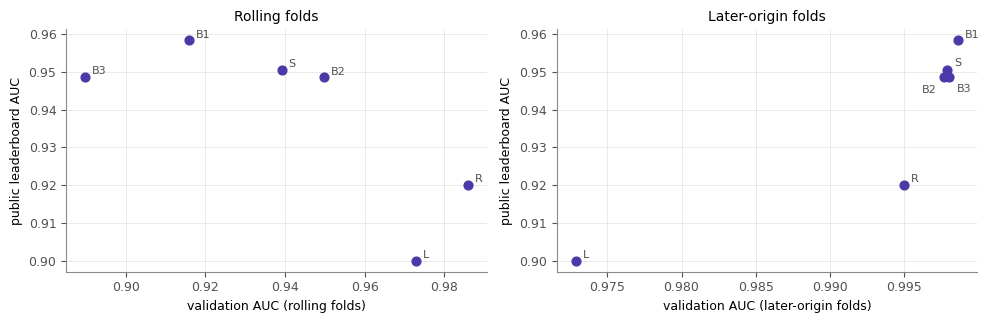

In [14]:
if RUN_EXTRA:
    sup, lic, ir, mlp_pred = PRED["sup_ens"], PRED["lic_ens"], PRED["ir_ens"], PRED["sup_mlp"]

    # (submission, public LB score, validation predictions of the same method on every fold)
    LB = [
        ("S: supervised ensemble only", 0.95047, sup),
        ("L: licit detector only", 0.90, {f: 1 - lic[f] for f in ALL}),
        ("R: supervised x licit detector (ratio)", 0.92, {f: combine(sup[f], lic[f]) for f in ALL}),
        ("B1: blend default, w = 0.5", 0.95830, blend(sup, ir, 0.5)),
        ("B2: supervised + 0.2 MLP", 0.94851, {f: 0.8 * lgt(sup[f]) + 0.2 * lgt(mlp_pred[f]) for f in ALL}),
        ("B3: supervised - 0.2 x unlabelled-like", 0.94869, {f: lgt(sup[f]) - 0.2 * lgt(1 - lic[f], 1e-3) for f in ALL}),
    ]

    rows = []
    for name, lb_score, scores in LB:
        rows.append({"submission": name, "public LB": lb_score,
                    "rolling mean": np.mean([roc_auc_score(Y_VAL[f], scores[f]) for f in ROLL]),
                    "later mean": np.mean([roc_auc_score(Y_VAL[f], scores[f]) for f in LATE]),
                    "later low-range": np.nanmean([low_range_auc(f, scores[f]) for f in LATE])})
    lbt = pd.DataFrame(rows).set_index("submission")
    lbt.to_csv(f"{OUT_DIR}/leaderboard_vs_validation.csv")
    print(lbt.round(4).to_string())
    print("\nSpearman correlation with the public leaderboard across these submissions:")
    print(lbt.corr(method="spearman")["public LB"].drop("public LB").round(2).to_string())

    # scatter: public LB against validation AUC, one panel per set of folds
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
    label_offsets = {"S": (5, 3), "B2": (-16, -11), "B3": (5, -11)}   # stop labels overlapping on the right panel
    for a, col, title in [(ax[0], "rolling mean", "Rolling folds"), (ax[1], "later mean", "Later-origin folds")]:
        a.scatter(lbt[col], lbt["public LB"], s=40, color=C_IR)
        for name, row in lbt.iterrows():
            tag = name.split(":")[0]
            offset = label_offsets.get(tag, (5, 2)) if col == "later mean" else (5, 2)
            a.annotate(tag, (row[col], row["public LB"]), fontsize=8, color="#52514e", xytext=offset, textcoords="offset points")
        a.set_xlabel(f"validation AUC ({title.lower()})")
        a.set_ylabel("public leaderboard AUC")
        a.set_title(title)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/figures/leaderboard_vs_validation.png", dpi=150)
    plt.show()

The rolling folds rank the submissions almost in reverse. They favour anything that flags unusual-looking transactions, which is what the leaderboard punished. The later-origin folds get the order mostly right.

A reason could be that the test period has few new and unusual-looking illicit patterns, while most of its unusual-looking transactions are licit. The rolling folds give too much weight to the one big novelty event in the training data (the new illicit chains around step 24).

Hence, from here onwards, I chose models using the later-origin folds and use the leaderboard as a final check.

## 10. Final model: component strength and blend weight

2 versions of each ensemble are compared on the later-origin folds: the default settings and a slower-learning version (lower learning rate, more trees).

In [15]:
if RUN_EXTRA:
    # slower-learning version of both ensembles (later-origin folds only)
    for part in ["sup", "ir"]:
        for k, mk in SETS["slow"][part]:
            run_cv(f"{part}_{k}_slow", part, FEATS, mk, folds=LATE)
        PRED[f"{part}_ens_slow"] = average([f"{part}_{k}_slow" for k in ["lgb", "xgb", "cat"]], LATE)

    # try different blend weights for each component set
    header("later")
    for set_name, sup, ir in [("default", PRED["sup_ens"], PRED["ir_ens"]), ("slow", PRED["sup_ens_slow"], PRED["ir_ens_slow"])]:
        for w in [0.3, 0.5, 0.65, 0.8, 0.9]:
            evaluate(f"{set_name} components, w = {w}", blend(sup, ir, w, LATE), family="later", group="E. final model")

    # average the default and slow sets, then try the weights I submitted (final choice: w = 1.0)
    sup_both = {f: (PRED["sup_ens"][f] + PRED["sup_ens_slow"][f]) / 2 for f in LATE}
    ir_both = {f: (PRED["ir_ens"][f] + PRED["ir_ens_slow"][f]) / 2 for f in LATE}
    for w in [0.85, 0.9, 0.95, 1.0]:
        evaluate(f"both component sets, w = {w}", blend(sup_both, ir_both, w, LATE), family="later", group="E. final model")

  fitted sup_lgb_slow on 5 folds (53s)
  fitted sup_xgb_slow on 5 folds (12s)
  fitted sup_cat_slow on 5 folds (57s)
  fitted ir_lgb_slow on 5 folds (80s)
  fitted ir_xgb_slow on 5 folds (44s)
  fitted ir_cat_slow on 5 folds (143s)
                                                           <=24 -> 25-35  <=26 -> 27-35  <=28 -> 29-35  <=30 -> 31-35  <=32 -> 33-35
default components, w = 0.3                                0.9982 0.9986 0.9981 0.9990 0.9985 | mean 0.9985 | worst 0.9981 | low-range 0.9804
default components, w = 0.5                                0.9983 0.9987 0.9983 0.9993 0.9987 | mean 0.9986 | worst 0.9983 | low-range 0.9824
default components, w = 0.65                               0.9982 0.9986 0.9983 0.9993 0.9988 | mean 0.9986 | worst 0.9982 | low-range 0.9826
default components, w = 0.8                                0.9978 0.9982 0.9979 0.9993 0.9988 | mean 0.9984 | worst 0.9978 | low-range 0.9807
default components, w = 0.9                                0.9969 0

Upon validation, the best weight is around 0.5 to 0.65, and the slower components are slightly better. However, on the public leaderboard, the score kept rising as the weight went up, for every setting (default: 0.958 at 0.5 and 0.961 at 0.8; slow: 0.955 at 0.5 and 0.961 at 0.9; both settings averaged: 0.96105 at 0.85, 0.96141 at 0.9, 0.96162 at 0.95 and 0.96168 at 1.0). At a weight of 1, the supervised ensemble drops out completely, so my final model is the illicit-vs-rest ensemble on its own, averaging both settings (`FINAL_SET = "both"`, `FINAL_W = 1.0`).

This is the only decision I based on the public leaderboard. I think the risk of overfitting to it is small as the trend was the same across 10 submissions, and the last few steps differ by less than 0.001, which is within the noise of the 30% public split. However, validation preferred a weight of about 0.5, so I kept the even blend (B1) as my second final submission in case the private leaderboard behaves more like validation.

## 11. Results

In [16]:
res = pd.DataFrame(RESULTS)
res.to_csv(f"{OUT_DIR}/cv_results.csv", index=False)
with pd.option_context("display.max_columns", 30, "display.width", 250):
    print(res.drop(columns=["group"]).to_string(index=False))

 family                                                 model  <=5 -> 6-19  <=10 -> 11-24  <=15 -> 16-29  <=20 -> 21-34  <=25 -> 26-35  <=30 -> 31-35  mean AUC  worst AUC  <=24 -> 25-35  <=26 -> 27-35  <=28 -> 29-35  <=32 -> 33-35  low-range AUC
rolling                         Logistic regression [raw 165]       0.9528         0.9685         0.9303         0.8559         0.9415         0.9653    0.9357     0.8559            NaN            NaN            NaN            NaN            NaN
rolling                               Random forest [raw 165]       0.9185         0.9497         0.8755         0.7544         0.9922         0.9968    0.9145     0.7544            NaN            NaN            NaN            NaN            NaN
rolling                               MLP (128, 64) [raw 165]       0.9208         0.9784         0.9626         0.9174         0.9843         0.9882    0.9586     0.9174            NaN            NaN            NaN            NaN            NaN
rolling         

### Operating-point metrics
The competition is scored on ROC-AUC, but in practice an AML team can only review a limited number of alerts. Hence, for 2 of the later-origin folds, I compared the supervised ensemble with the final blend on more practical metrics: PR-AUC, recall when only 1% or 5% of licit transactions are flagged, and precision and recall at the threshold with the best F1 score.

In [17]:
def operating_metrics(y, s):
    fpr, tpr, _ = roc_curve(y, s)
    prec, rec, _ = precision_recall_curve(y, s)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    i = np.argmax(f1)
    return {"ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
            "recall @ 1% FPR": np.interp(0.01, fpr, tpr), "recall @ 5% FPR": np.interp(0.05, fpr, tpr),
            "best F1": f1[i], "precision at best F1": prec[i], "recall at best F1": rec[i]}

if FINAL_SET == "slow" and "sup_ens_slow" in PRED:
    op_set, final_cv = "slow", blend(PRED["sup_ens_slow"], PRED["ir_ens_slow"], FINAL_W, LATE)
elif FINAL_SET == "both" and "sup_ens_slow" in PRED:
    op_set = "both"
    final_cv = blend({f: (PRED["sup_ens"][f] + PRED["sup_ens_slow"][f]) / 2 for f in LATE}, {f: (PRED["ir_ens"][f] + PRED["ir_ens_slow"][f]) / 2 for f in LATE}, FINAL_W, LATE)
else:
    op_set, final_cv = "default", blend(PRED["sup_ens"], PRED["ir_ens"], FINAL_W, LATE)
rows = {}
for f in [(24, 25, 35), (30, 31, 35)]:
    rows[f"supervised ensemble, {fname(f)}"] = operating_metrics(Y_VAL[f], PRED["sup_ens"][f])
    rows[f"final blend ({op_set} components, w = {FINAL_W}), {fname(f)}"] = operating_metrics(Y_VAL[f], final_cv[f])
ops = pd.DataFrame(rows).T.round(4)
ops.to_csv(f"{OUT_DIR}/operating_metrics.csv")
print(ops.to_string())

                                                       ROC-AUC  PR-AUC  recall @ 1% FPR  recall @ 5% FPR  best F1  precision at best F1  recall at best F1
supervised ensemble, <=24 -> 25-35                      0.9975  0.9905           0.9593           0.9860   0.9592                0.9625             0.9558
final blend (both components, w = 1.0), <=24 -> 25-35   0.9947  0.9831           0.9207           0.9677   0.9388                0.9631             0.9158
supervised ensemble, <=30 -> 31-35                      0.9987  0.9938           0.9841           0.9899   0.9761                0.9740             0.9783
final blend (both components, w = 1.0), <=30 -> 31-35   0.9990  0.9953           0.9710           0.9942   0.9708                0.9794             0.9623


## 12. Final model and submission
Every component is refitted on all 35 training steps: the supervised ensemble on the 31,235 labelled transactions,
the illicit-vs-rest ensemble on all 141,772. The final score is the logit blend with weight `FINAL_W`. With
`FINAL_W = 1.0` the supervised ensemble gets no weight, so the final score is simply the illicit-vs-rest ensemble's
probability.

In [18]:
def fit_predict_full(target, cols, make_model):
    tr, y = target_of(TR, target)
    return make_model().fit(tr[cols].values, y).predict_proba(TE[cols].values)[:, 1]

use_sets = ["default", "slow"] if FINAL_SET == "both" else [FINAL_SET]
test_sup, test_ir = [], []
for set_name in use_sets:
    test_sup += [fit_predict_full("sup", FEATS, mk) for _, mk in SETS[set_name]["sup"]]
    test_ir += [fit_predict_full("ir", FEATS, mk) for _, mk in SETS[set_name]["ir"]]
p_sup, p_ir = np.mean(test_sup, axis=0), np.mean(test_ir, axis=0)
final_score = sigmoid((1 - FINAL_W) * lgt(p_sup) + FINAL_W * lgt(p_ir))

def write_submission(score, filename):
    sub = pd.DataFrame({"index": test["index"].values, "target": score})
    assert len(sub) == len(sample_sub) and (sub["index"].values == sample_sub["index"].values).all()
    assert sub.target.notna().all() and sub.target.between(0, 1).all()
    sub.to_csv(f"{OUT_DIR}/{filename}", index=False)
    print(f"wrote {filename}: {len(sub)} rows, target mean {sub.target.mean():.4f}")

write_submission(final_score, "submission_final.csv")

wrote submission_final.csv: 15329 rows, target mean 0.0203


## 13. Summary

* Validating "out of time" was not enough by itself. The rolling folds were dominated by one unusual event in the training data, and they led me to a model that scored 0.03 lower on the leaderboard.

* The unlabelled transactions turned out to be the most useful extra data, but only when I treated them as normal background (illicit vs everything else), not as a sign that anything unusual is illicit.

* Compared with that, graph features and an MLP made little difference.
